# Desarrollo y pruebas del modelo base (Baseline-model)

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Normalization, Conv1D, Dense

# Configuración de rutas del proyecto
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

from src.utils import *
from src.models import *

In [2]:
## Levanto el dataset (unicamente los datos de acelerometro)
data = extraer_datos_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset'), file = 'Event_FallAIIDDataSet_*.txt', sensors= ['AccX','AccY','AccZ','Bar','Temp'])

## Extraigo los Tags del dataset
tags, activity= extraer_tags_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset'), file = 'Event_FallAIIDDataSet_*.txt')


In [3]:
data_entrenamiento, data_val, tags_entrenamiento, y_val , _ , activity_val = train_test_split(data,tags,activity, test_size=0.2, random_state=21)

data_train, data_test, y_train, y_test,  = train_test_split(data,tags, test_size=0.25, random_state=21)

# data_train_presion, data_test_presion, y_train_presion, y_test_presion = train_test_split(data_sensores,tags_presion, test_size=0.2, random_state=21)

In [4]:


# def rotacion(datos, matriz_rot):
#     if datos.ndim == 4:
#         datos = datos[:,:,:,0]

#     data = datos.copy()

#     for indx, t in enumerate(data):
#         data[indx] = t.dot(matriz_rot)

#     data =  np.expand_dims(data, axis=-1)
    
#     return data



# matriz_rot = np.array([
#     [-1,  0,  0],
#     [ 0, -1,  0],
#     [ 0,  0,  1]
# ])

In [5]:
data_presion = data_test[:,:,3:5]
alturas_mediciones = calcular_altura(data_presion,20)
features_extracted_presion = extraer_features(alturas_mediciones) # inputs modelo de sensor de presión

data_acelerometro = data_test[:,:,:3]



In [6]:
data_presion_val = data_val[:,:,3:5]
alturas_mediciones_val = calcular_altura(data_presion_val,20)
features_extracted_presion_val = extraer_features(alturas_mediciones_val) # inputs modelo de sensor de presión

data_acelerometro_val = data_val[:,:,:3]

# Prueba de rotacion de acelerometro
# data_acelerometro_val = rotacion(data_val[:,:,:3], matriz_rot)[:,:,:,0]


In [7]:
data_presion_full = data[:,:,3:5]
alturas_mediciones_full = calcular_altura(data_presion_full,20)
features_extracted_presion_full = extraer_features(alturas_mediciones_full) # inputs modelo de sensor de presión

data_acelerometro_full = data[:,:,:3]

Para combinar ambas señales se pueden tomar dos metodologias. La primera consiste en promediar ambas salidas de cada modelo, puediendo incluso utilizar pesos distintos en cada uno de ellos. El resultado es una probabilidad conjunta que luego se puede comparar con un valor humbral para determinar si hubo o no un evento de caida.
El segundo metodo de combinacion de señales consiste en un proceso de descarte sencuencial, donde una primer instancia filtra aquellos eventos que muy probablemente no tengan una disiminucion en la altura y luego se utiliza el resultado de la deteccion del acelerometro para evaluar si es que el evento condice con una caida.


In [8]:
# metodo = "Secuencial" # "Promedio ponderado"
metodo = "Promedio ponderado"


## NN para altura + CNN Acelerometro


In [9]:
modelo_sensor_presion= tf.keras.models.load_model(str(MODELS_DIR / "modelo_barometro_nn.keras"))
modelo_sensor_acelerometro= tf.keras.models.load_model(str(MODELS_DIR / "modelo_acelerometro.keras"))

y_pred_presion = modelo_sensor_presion.predict(features_extracted_presion)
y_pred_acelerometro = modelo_sensor_acelerometro.predict(data_acelerometro)

y_pred_presion_val = modelo_sensor_presion.predict(features_extracted_presion_val)
y_pred_acelerometro_val = modelo_sensor_acelerometro.predict(data_acelerometro_val)

y_pred_presion_full = modelo_sensor_presion.predict(features_extracted_presion_full)
y_pred_acelerometro_full = modelo_sensor_acelerometro.predict(data_acelerometro_full)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


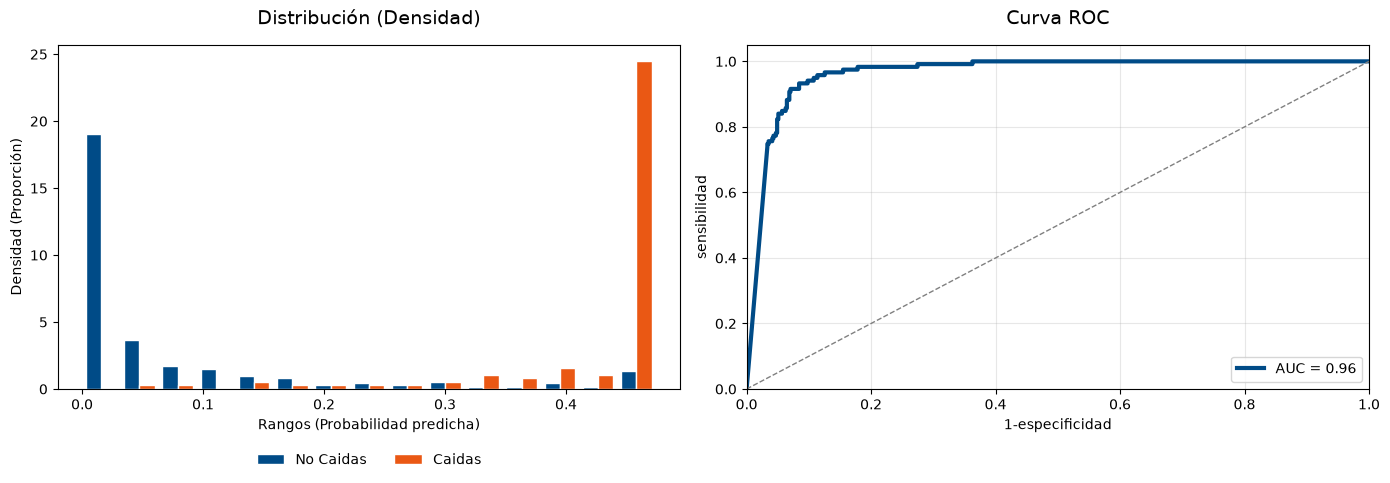

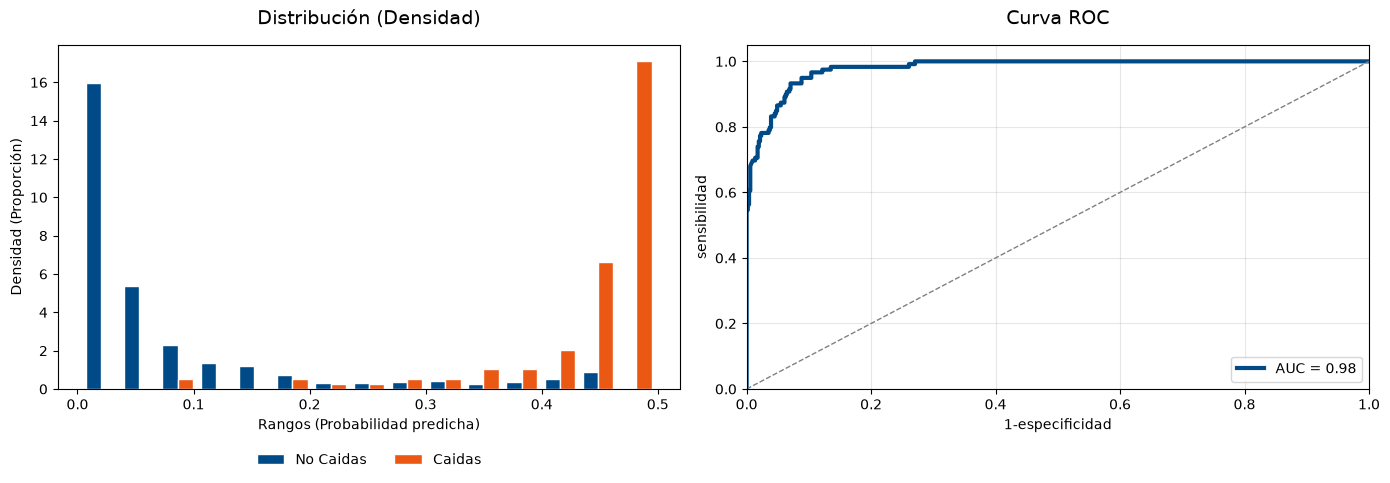

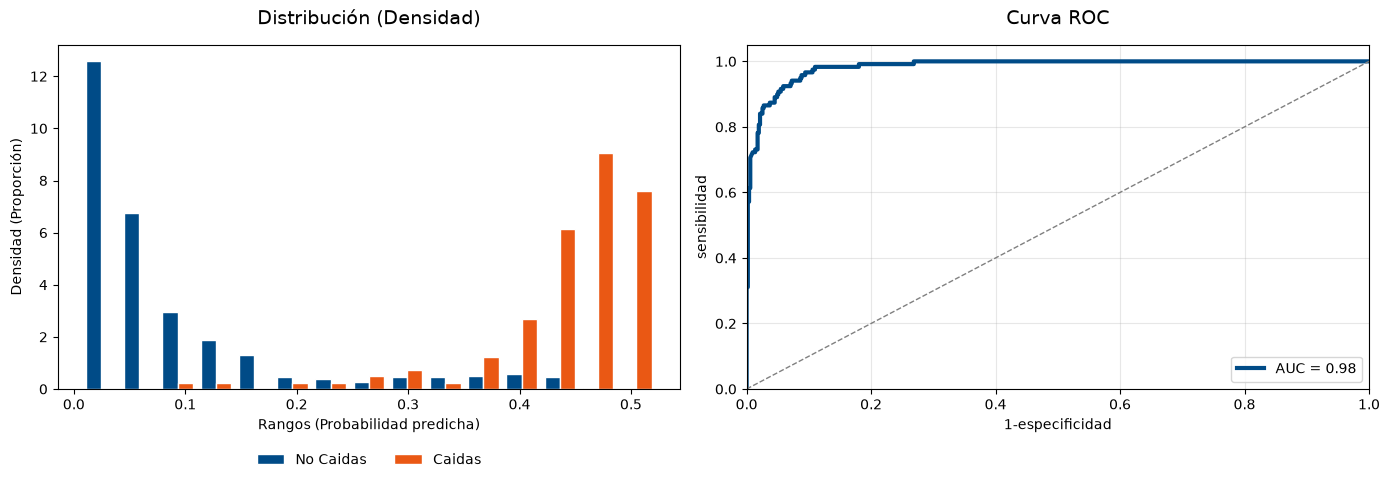

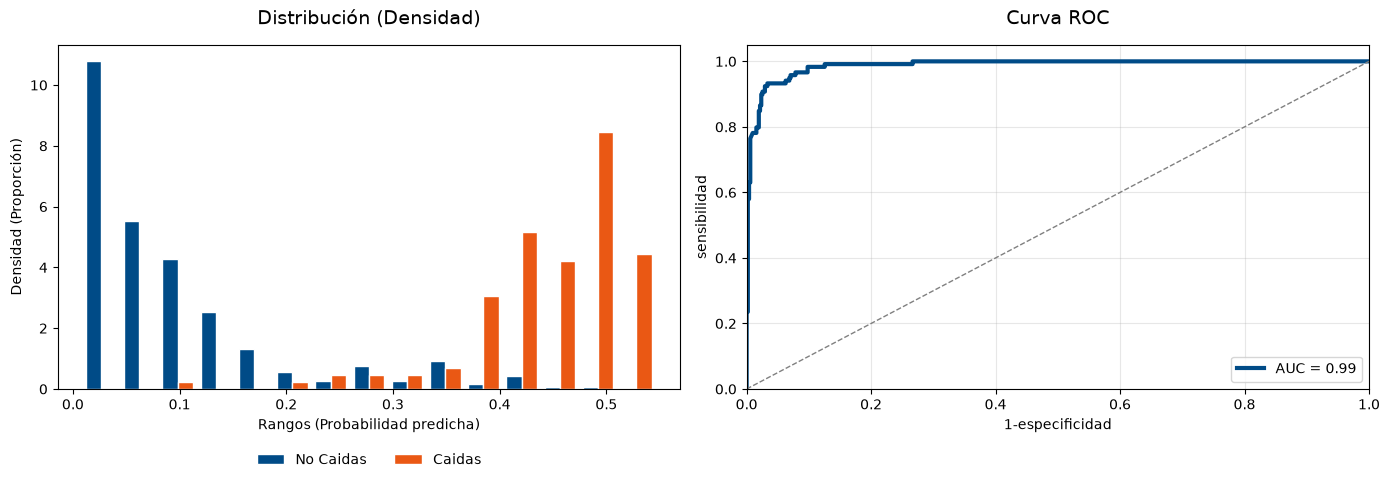

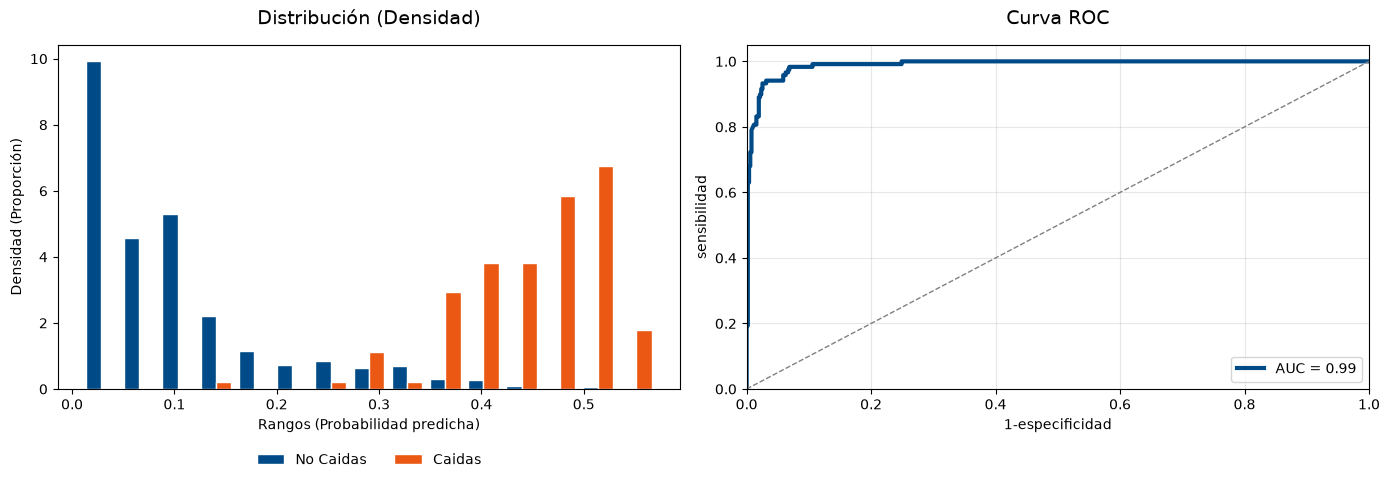

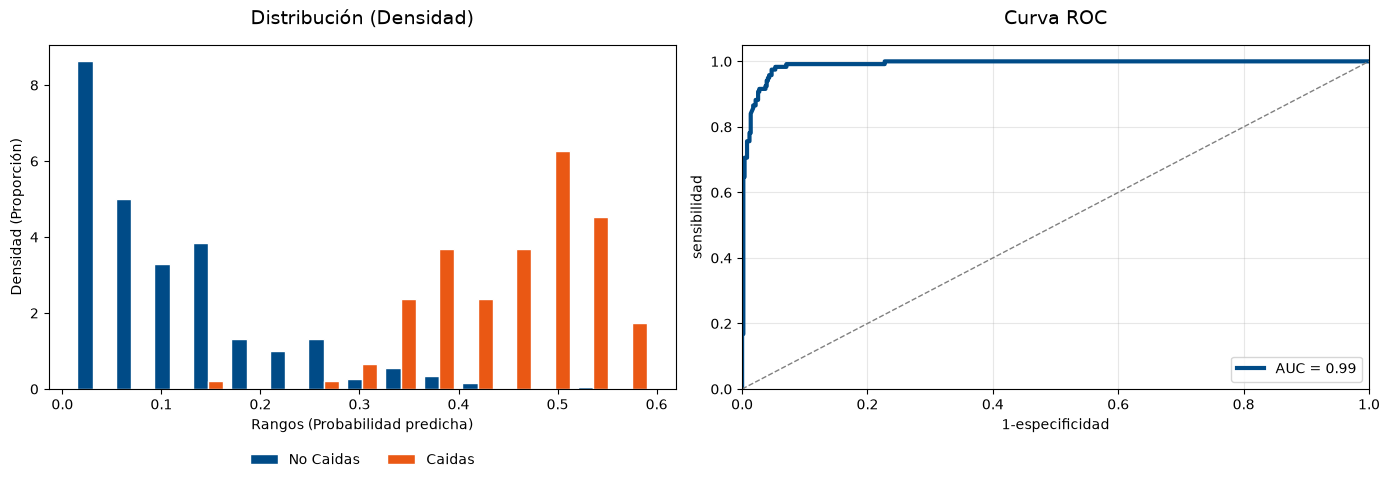

In [10]:
for i in range(0,6,1):
    if metodo == "Promedio ponderado":
        K = 0.1 * i
        y_pred = (y_pred_presion * K + y_pred_acelerometro * (1- K)) 
        graficar_distribucion_y_roc(y_test, y_pred)

    if metodo == "Secuencial":
        h1 = 0.1 * i
        filtro = (y_pred_acelerometro > h1).astype(int)
        
        graficar_distribucion_y_roc(y_test, y_pred_presion*filtro)  


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.99      0.95      0.97       404
    FALL (1)       0.83      0.97      0.90        99

    accuracy                           0.96       503
   macro avg       0.91      0.96      0.93       503
weighted avg       0.96      0.96      0.96       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    385                 19
Real CAÍDA:       3                 96


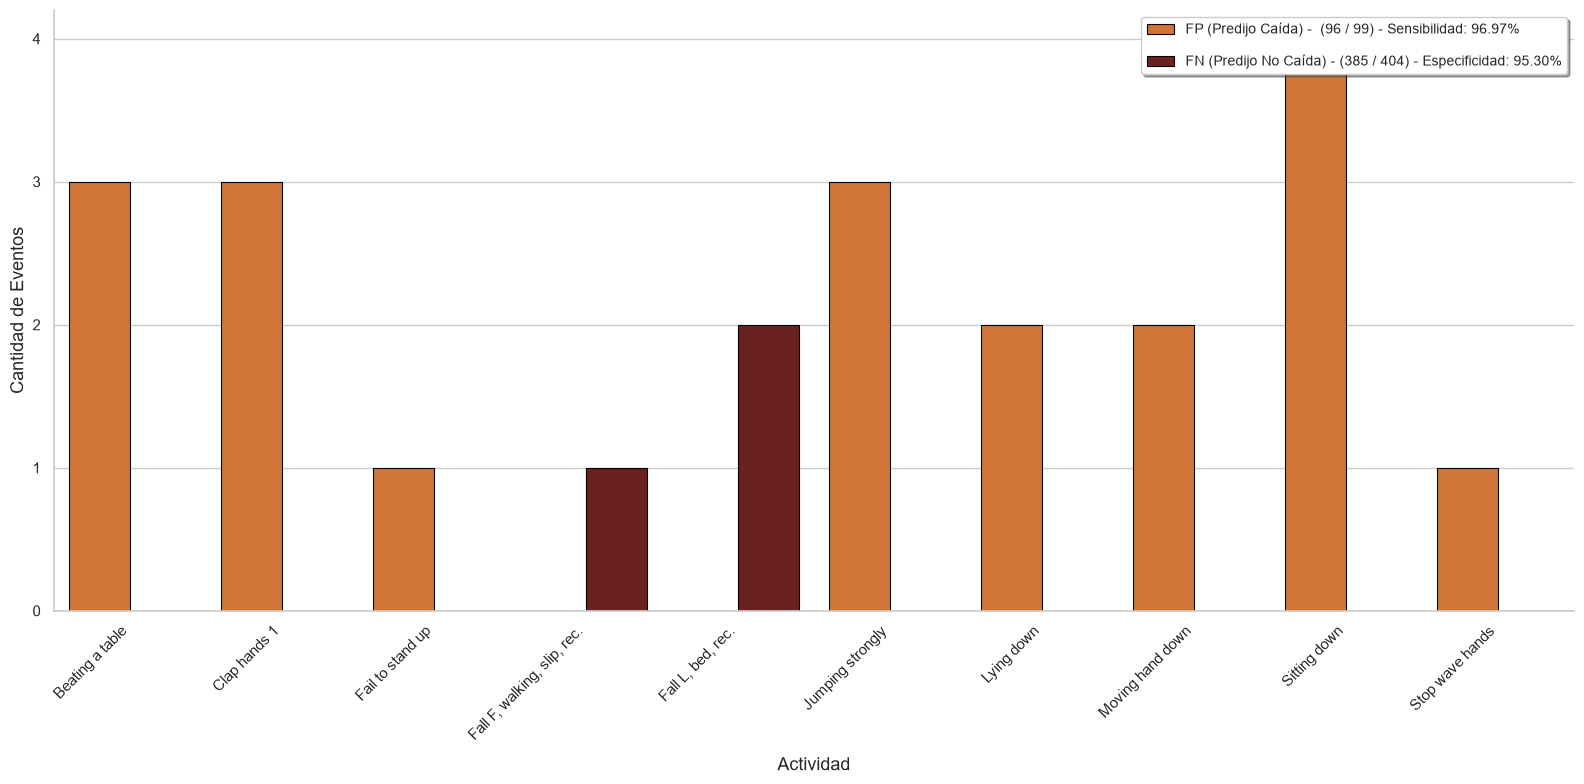

In [11]:
K = 0.5 # 0.5
threshold = 0.3    # 0.3

if metodo == "Promedio ponderado":
    y_pred = (y_pred_presion_val * K + y_pred_acelerometro_val * (1- K)) 
    y_pred = (y_pred > threshold ).astype(int)

###############

h1 = 0.1
h2= 0.2
if metodo == "Secuencial":

    filtro = (y_pred_acelerometro_val > h1).astype(int)
    y_pred = (y_pred_presion_val*filtro > h2 ).astype(int)

stats_perfom(y_pred, y_val, activity_val)


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.99      0.96      0.97      1992
    FALL (1)       0.85      0.97      0.91       523

    accuracy                           0.96      2515
   macro avg       0.92      0.96      0.94      2515
weighted avg       0.96      0.96      0.96      2515


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    1904                 88
Real CAÍDA:       16                 507


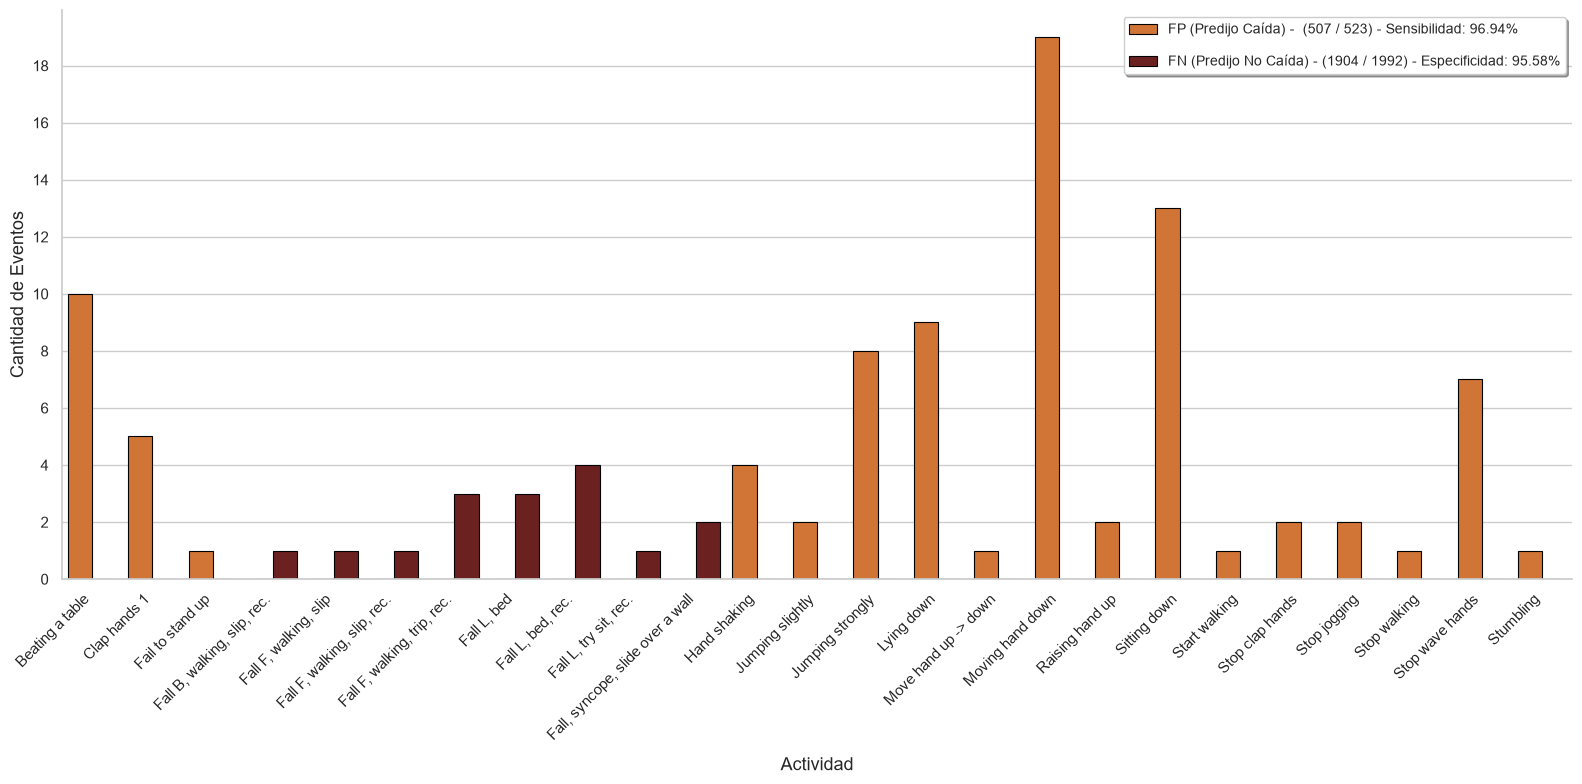

In [12]:

if metodo == "Promedio ponderado":
    y_pred = (y_pred_presion_full * K + y_pred_acelerometro_full * (1- K)) 
    y_pred = (y_pred > threshold ).astype(int)


if metodo == "Secuencial":
    filtro = (y_pred_acelerometro_full > h1).astype(int)
    y_pred = (y_pred_presion_full*filtro > h2 ).astype(int)

  

stats_perfom(y_pred, tags, activity)


## Fusion XGboost para altura + CNN Acelerometro


In [13]:
# metodo = "Secuencial" # "Promedio ponderado"
metodo = "Promedio ponderado"


In [14]:
import xgboost as xgb

# Creas una instancia vacía del modelo
modelo_sensor_presion = xgb.XGBClassifier()

# Cargas el archivo JSON
modelo_sensor_presion.load_model(str(MODELS_DIR / "modelo_barometro_xgboost.json"))
modelo_sensor_acelerometro= tf.keras.models.load_model(str(MODELS_DIR / "modelo_acelerometro.keras"))

y_pred_presion = modelo_sensor_presion.predict_proba(features_extracted_presion)[:,1:2]
y_pred_acelerometro = modelo_sensor_acelerometro.predict(data_acelerometro,batch_size = 1)

y_pred_presion_val = modelo_sensor_presion.predict_proba(features_extracted_presion_val)[:,1:2]
y_pred_acelerometro_val = modelo_sensor_acelerometro.predict(data_acelerometro_val,batch_size = 1)

y_pred_presion_full = modelo_sensor_presion.predict_proba(features_extracted_presion_full)[:,1:2]
y_pred_acelerometro_full = modelo_sensor_acelerometro.predict(data_acelerometro_full,batch_size = 1)


629/629 ━━━━━━━━━━━━━━━━━━━━ 0s 671us/step
503/503 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step
2515/2515 ━━━━━━━━━━━━━━━━━━━━ 2s 669us/step


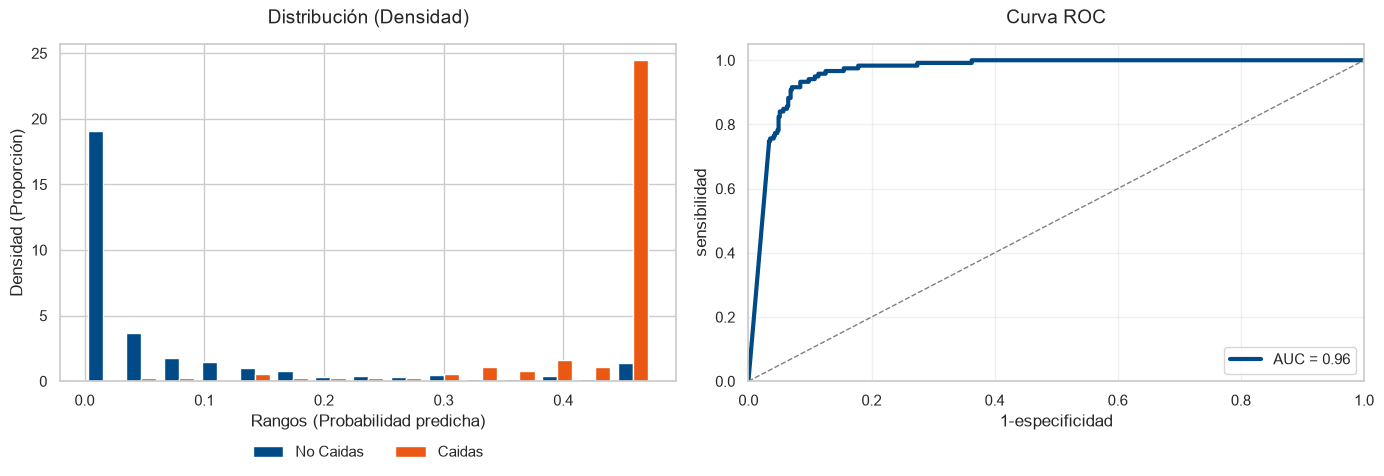

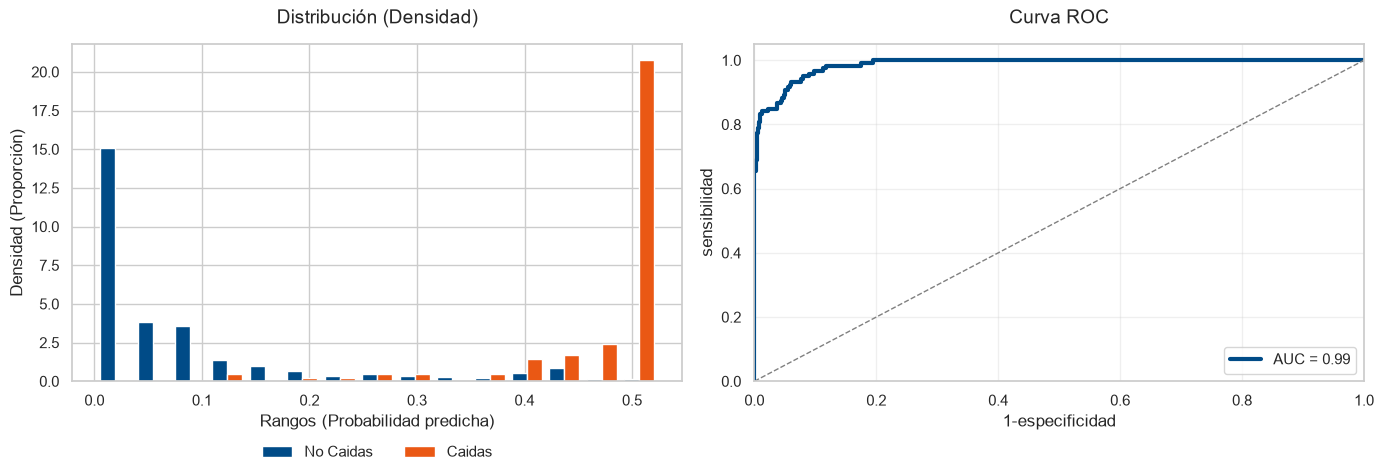

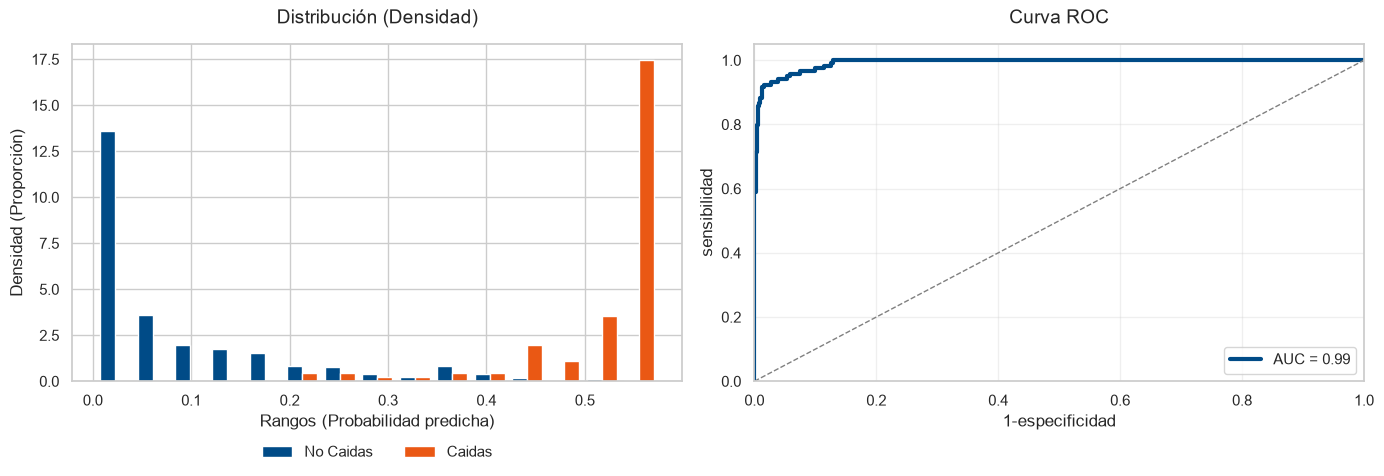

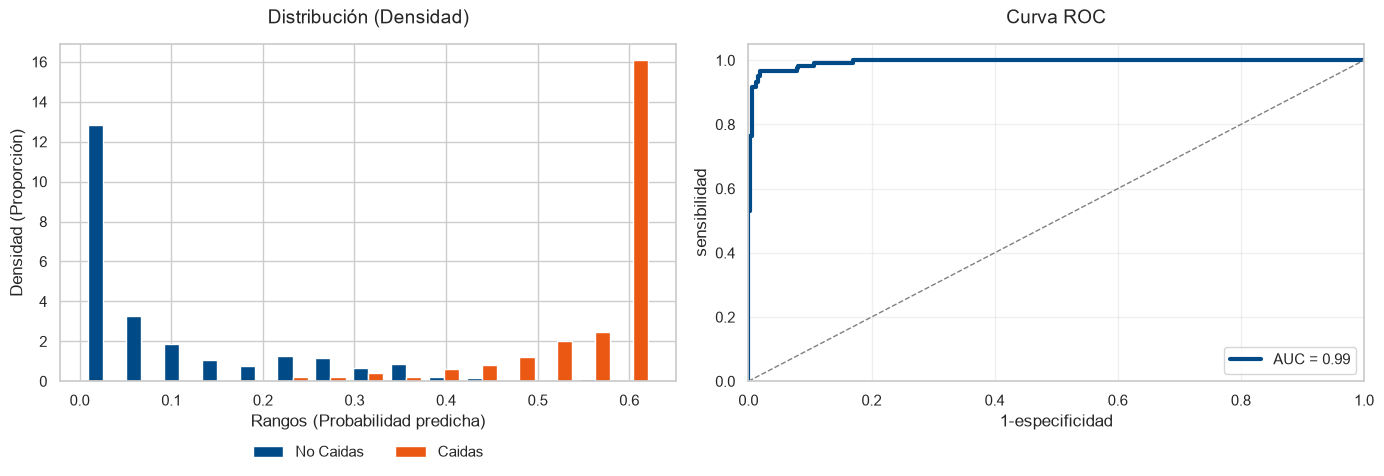

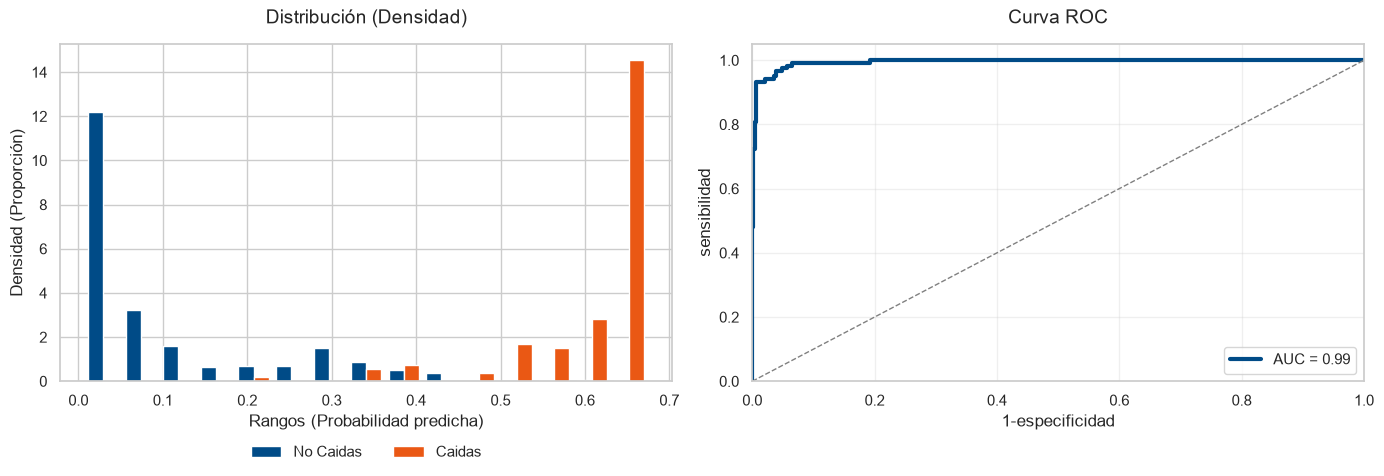

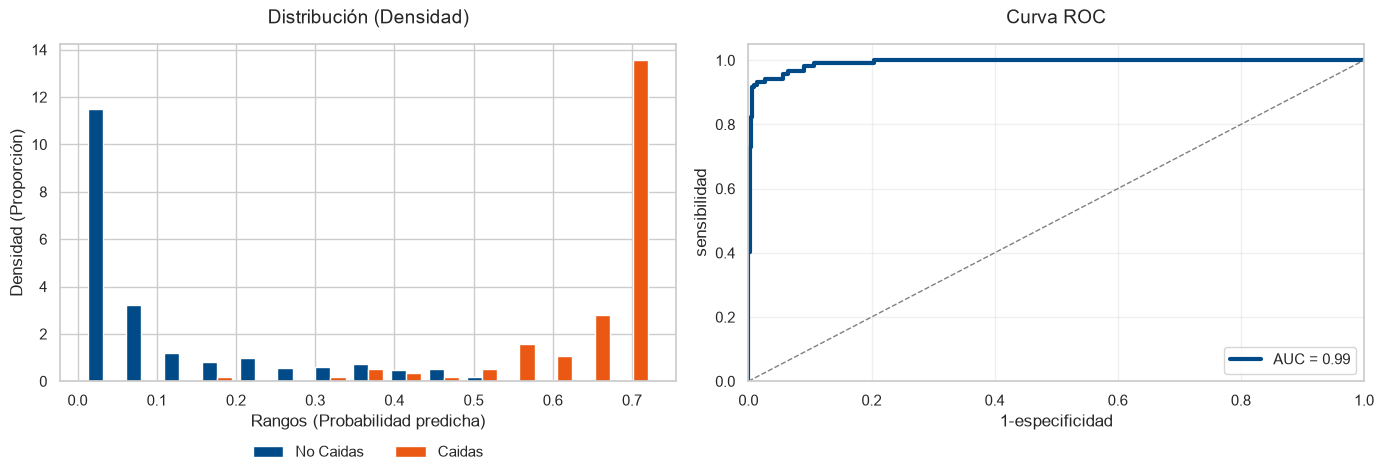

In [15]:
for i in range(0,6,1):
    if metodo == "Promedio ponderado":
        peso_barometro = 0.1 * i
        y_pred = (y_pred_presion * peso_barometro + y_pred_acelerometro * (1- peso_barometro)) 
        graficar_distribucion_y_roc(y_test, y_pred)

    if metodo == "Secuencial":
        H1 = 0.1 * i

        filtro = (y_pred_acelerometro > H1).astype(int)
        
        graficar_distribucion_y_roc(y_test, y_pred_presion*filtro)  


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.98      0.99      0.98       404
    FALL (1)       0.94      0.92      0.93        99

    accuracy                           0.97       503
   macro avg       0.96      0.95      0.96       503
weighted avg       0.97      0.97      0.97       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    398                 6
Real CAÍDA:       8                 91


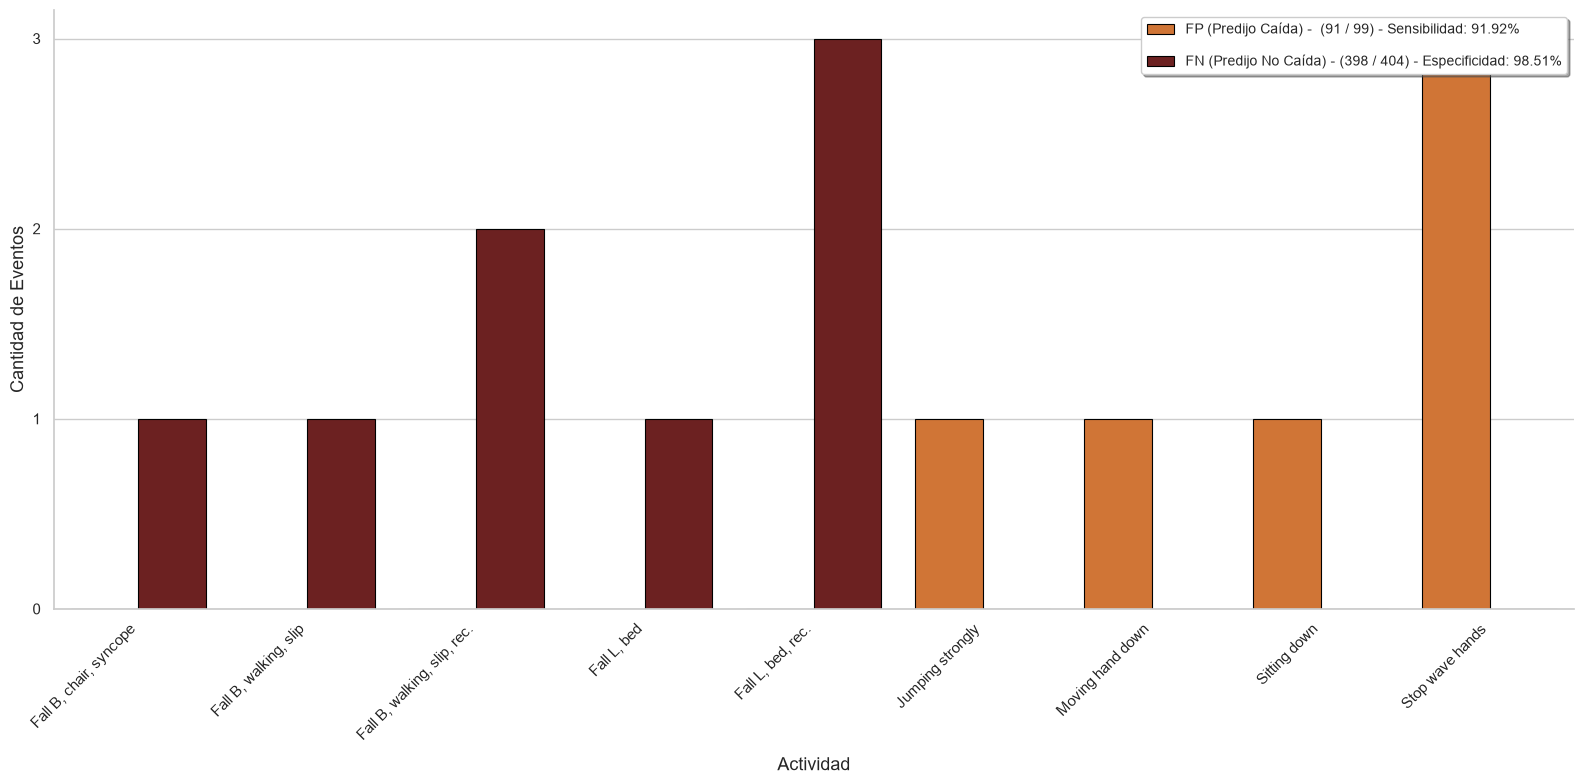

In [16]:

if metodo == "Promedio ponderado":
    K = 0.5
    H1 = 0.5
    y_pred = (y_pred_presion_val * K + y_pred_acelerometro_val * (1- K)) 
    y_pred = (y_pred > H1 ).astype(int)
    

if metodo == "Secuencial":
    H1= 0.1
    H2 = 0.4
    filtro = (y_pred_acelerometro_val > H1).astype(int)
    y_pred = (y_pred_presion_val*filtro > H2 ).astype(int)
  

stats_perfom(y_pred, y_val, activity_val)


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.99      0.99      0.99      1992
    FALL (1)       0.95      0.95      0.95       523

    accuracy                           0.98      2515
   macro avg       0.97      0.97      0.97      2515
weighted avg       0.98      0.98      0.98      2515


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    1967                 25
Real CAÍDA:       25                 498


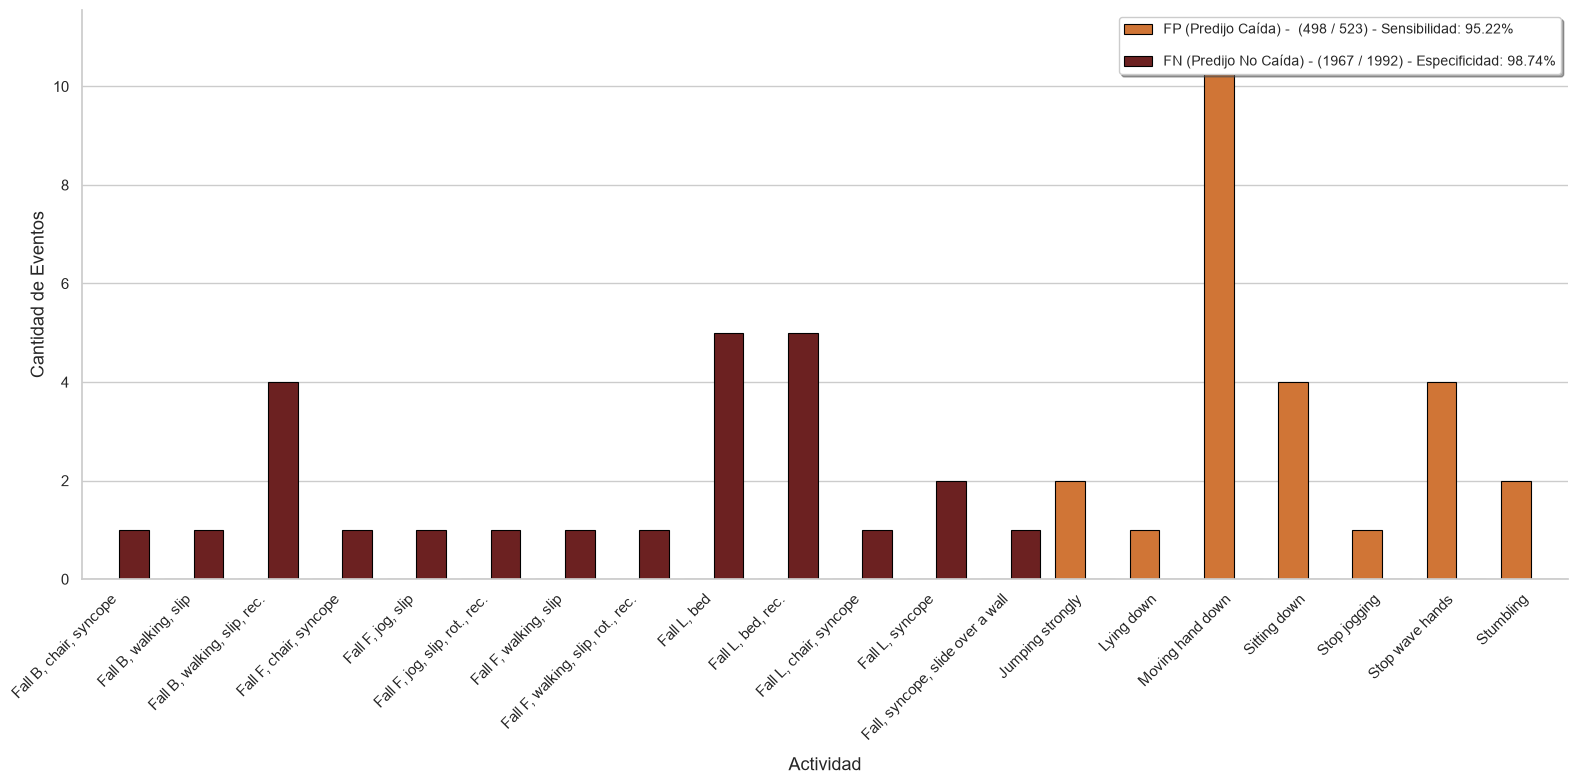

In [17]:

if metodo == "Promedio ponderado":
    y_pred = (y_pred_presion_full * K + y_pred_acelerometro_full * (1- K)) 
    y_pred = (y_pred > H1 ).astype(int)


if metodo == "Secuencial":
    y_pred = (y_pred_acelerometro_full > H1).astype(int)
    y_pred = (y_pred_presion_full *filtro > H2 ).astype(int)
  
stats_perfom(y_pred, tags, activity)


# CNN + SVM

In [18]:
import joblib
from sklearn.svm import SVC

modelo_sensor_presion = joblib.load(str(MODELS_DIR / "modelo_barometro_svm.joblib"))
modelo_sensor_acelerometro= tf.keras.models.load_model(str(MODELS_DIR / "modelo_acelerometro.keras"))


c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\.venv\Lib\site-packages\sklearn\base.py:525: Inconsis

In [19]:
# metodo = "Secuencial" # "Promedio ponderado"
metodo = "Promedio ponderado"


In [20]:

y_pred_presion = modelo_sensor_presion.predict(features_extracted_presion)
y_pred_acelerometro = modelo_sensor_acelerometro.predict(data_acelerometro)

y_pred_presion_val = modelo_sensor_presion.predict(features_extracted_presion_val)
y_pred_acelerometro_val = modelo_sensor_acelerometro.predict(data_acelerometro_val)

y_pred_presion_full = modelo_sensor_presion.predict(features_extracted_presion_full)
y_pred_acelerometro_full = modelo_sensor_acelerometro.predict(data_acelerometro_full)

y_pred_acelerometro =y_pred_acelerometro.reshape(1,-1)[0]
y_pred_acelerometro_val =y_pred_acelerometro_val.reshape(1,-1)[0]
y_pred_acelerometro_full =y_pred_acelerometro_full.reshape(1,-1)[0]



20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


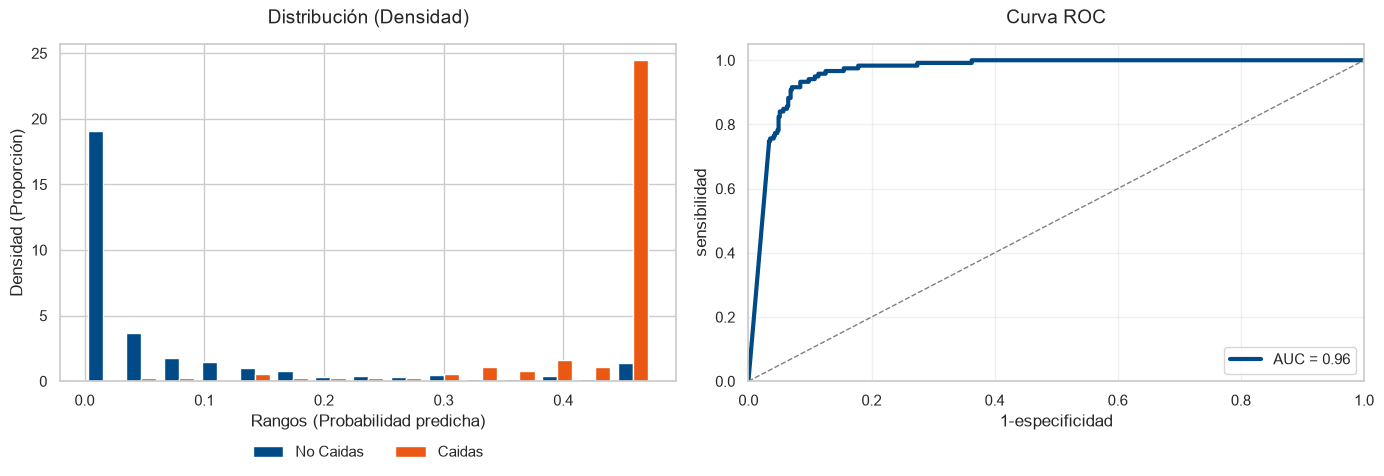

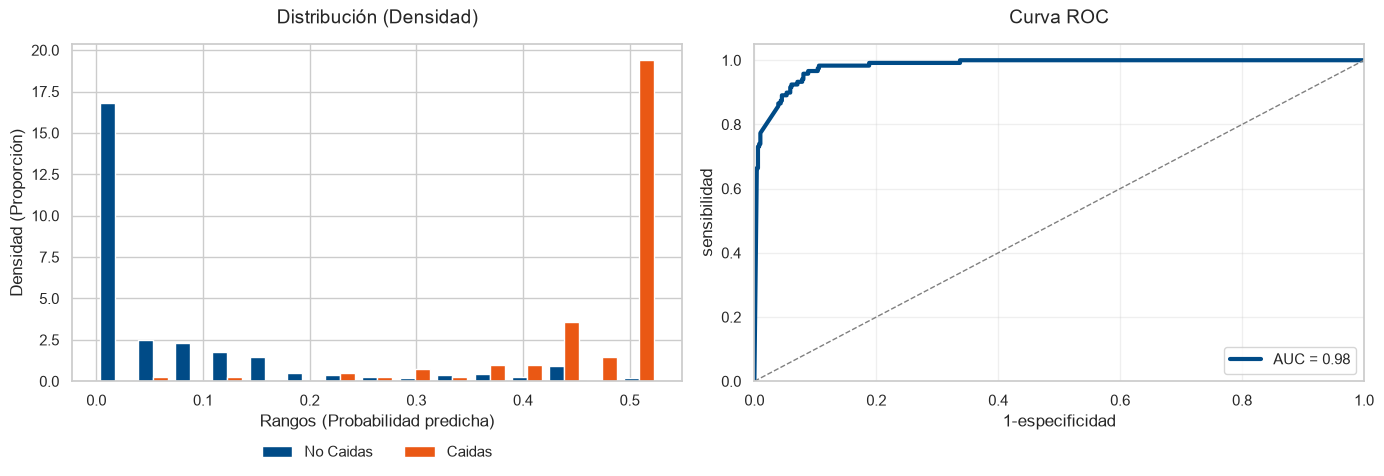

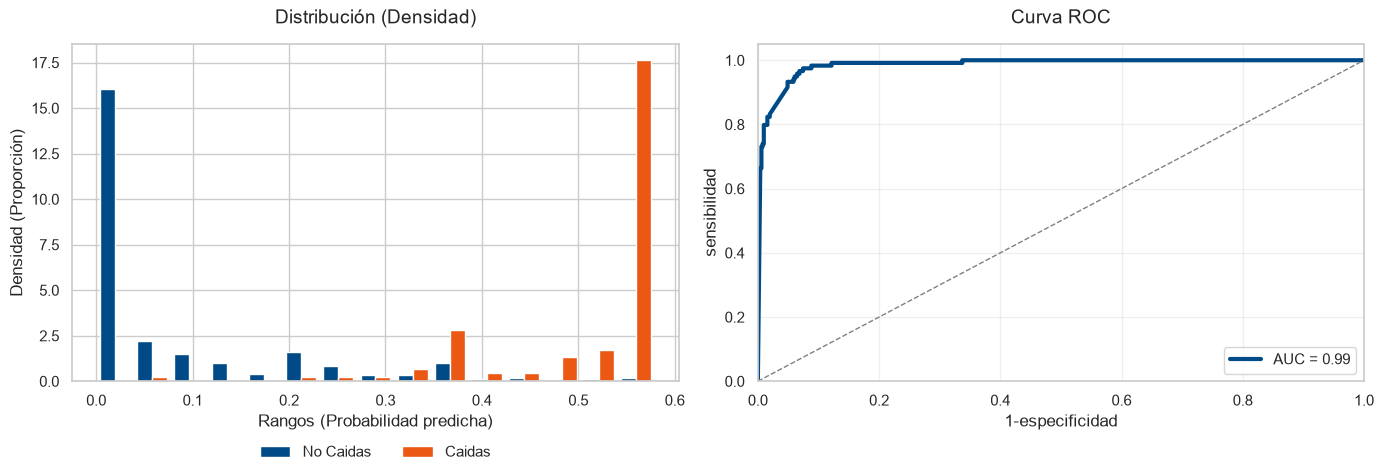

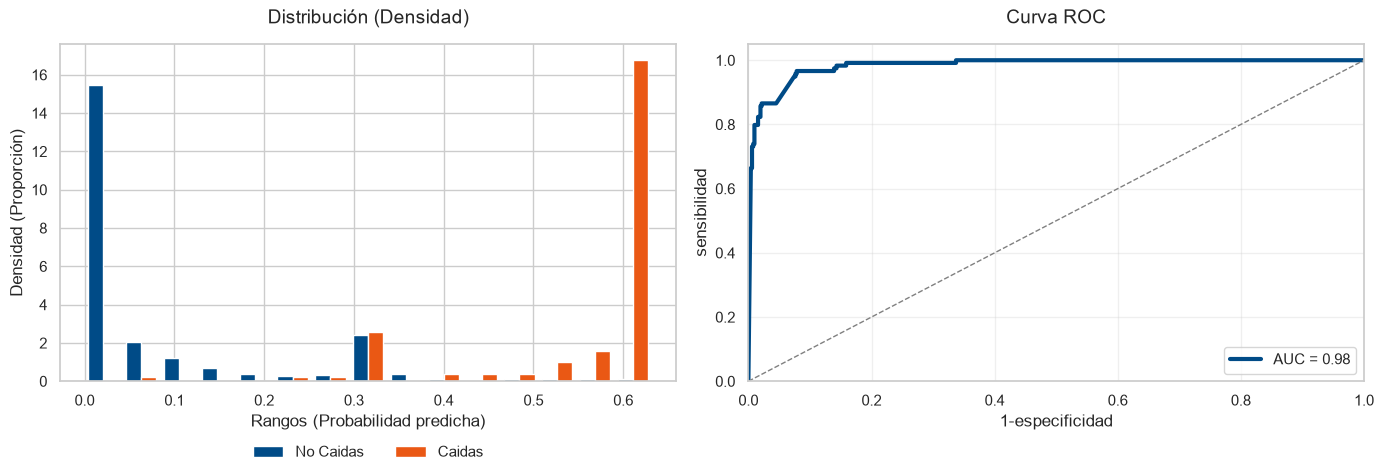

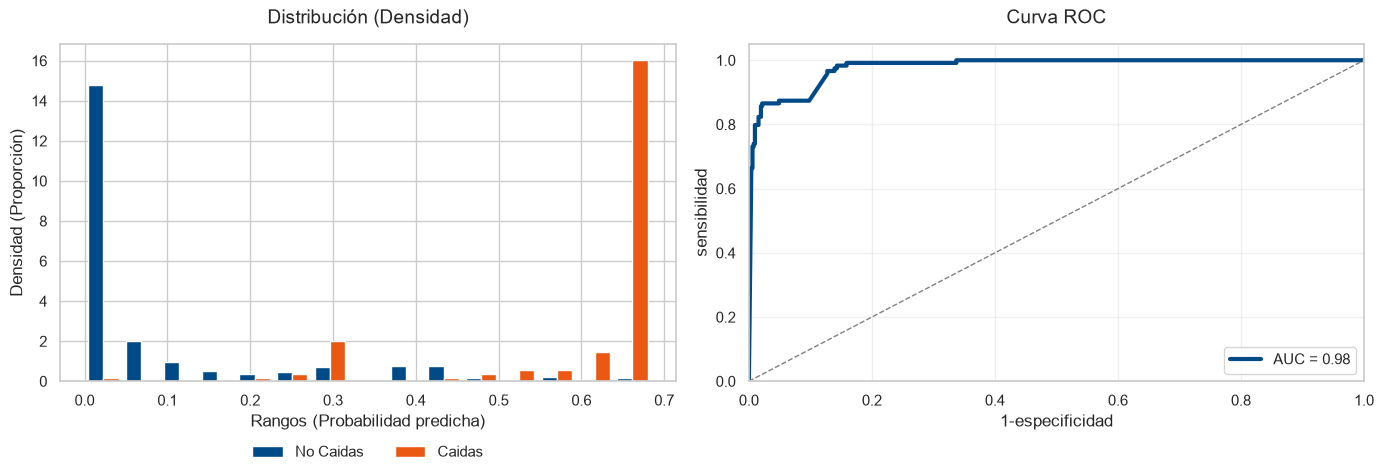

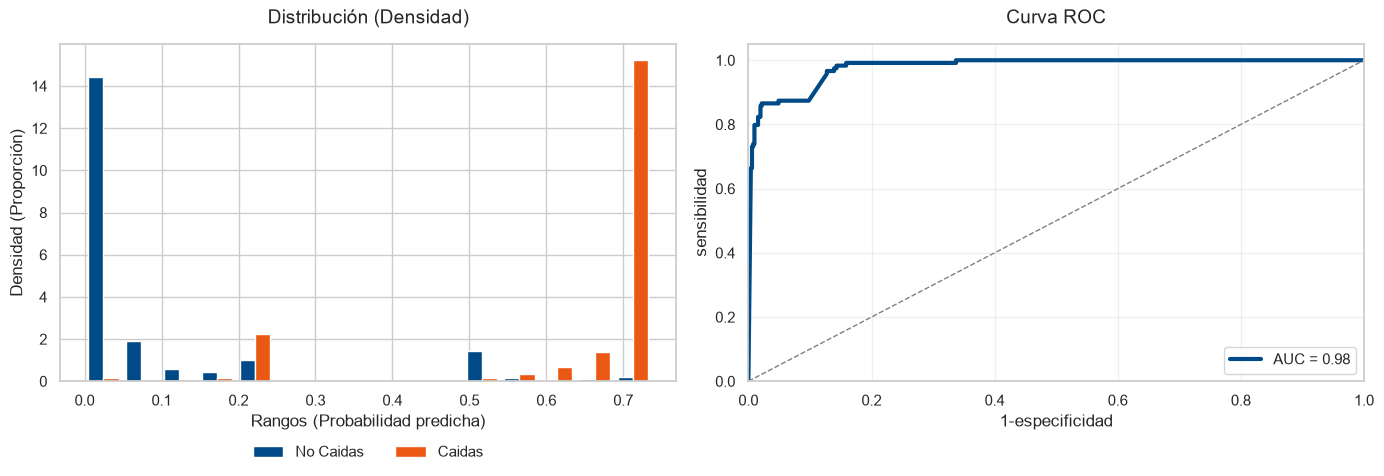

In [21]:
for i in range(0,6,1):
    if metodo == "Promedio ponderado":
        K = 0.1 * i
        y_pred = (y_pred_presion * K + y_pred_acelerometro * (1- K)) 
        graficar_distribucion_y_roc(y_test, y_pred)

    if metodo == "Secuencial":
        H1 = 0.1 * i
        filtro = (y_pred_acelerometro > H1).astype(int)
        graficar_distribucion_y_roc(y_test, y_pred_presion*filtro)  

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.97      0.97      0.97       404
    FALL (1)       0.88      0.87      0.87        99

    accuracy                           0.95       503
   macro avg       0.92      0.92      0.92       503
weighted avg       0.95      0.95      0.95       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    392                 12
Real CAÍDA:       13                 86


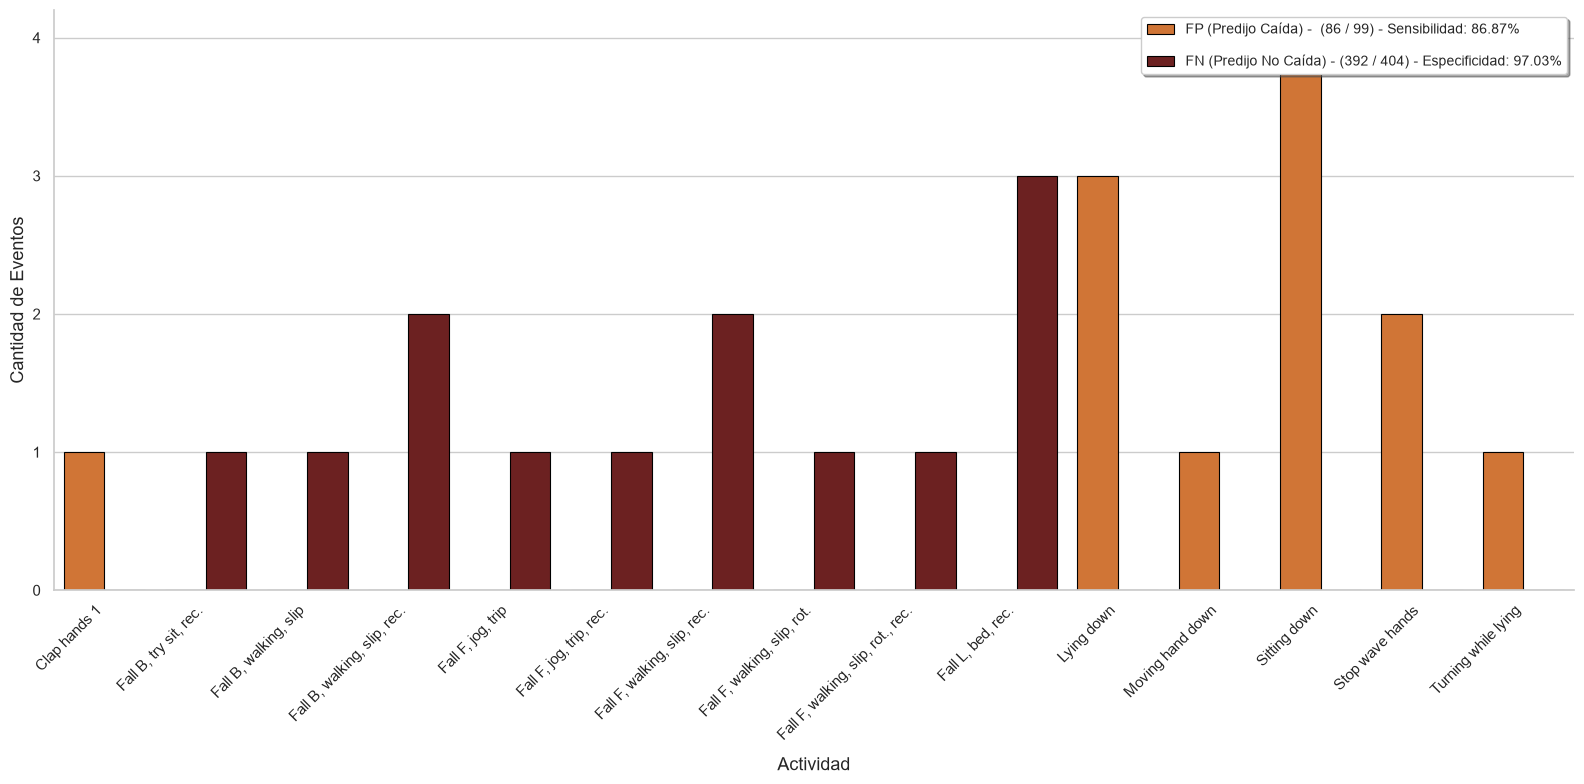

In [22]:

if metodo == "Promedio ponderado":
    
    K = 0.3
    H1 = 0.35

    y_pred = (y_pred_presion_val * K + y_pred_acelerometro_val * (1- K)) 
    y_pred = (y_pred > H1 ).astype(int)


if metodo == "Secuencial":
    H1= 0.2
    H2 = 0.5
    filtro = (y_pred_acelerometro_val > H1).astype(int)
    y_pred = (y_pred_presion_val*filtro > H2 ).astype(int)

stats_perfom(y_pred, y_val, activity_val)

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.97      0.97      0.97      1992
    FALL (1)       0.90      0.87      0.88       523

    accuracy                           0.95      2515
   macro avg       0.93      0.92      0.93      2515
weighted avg       0.95      0.95      0.95      2515


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    1939                 53
Real CAÍDA:       66                 457


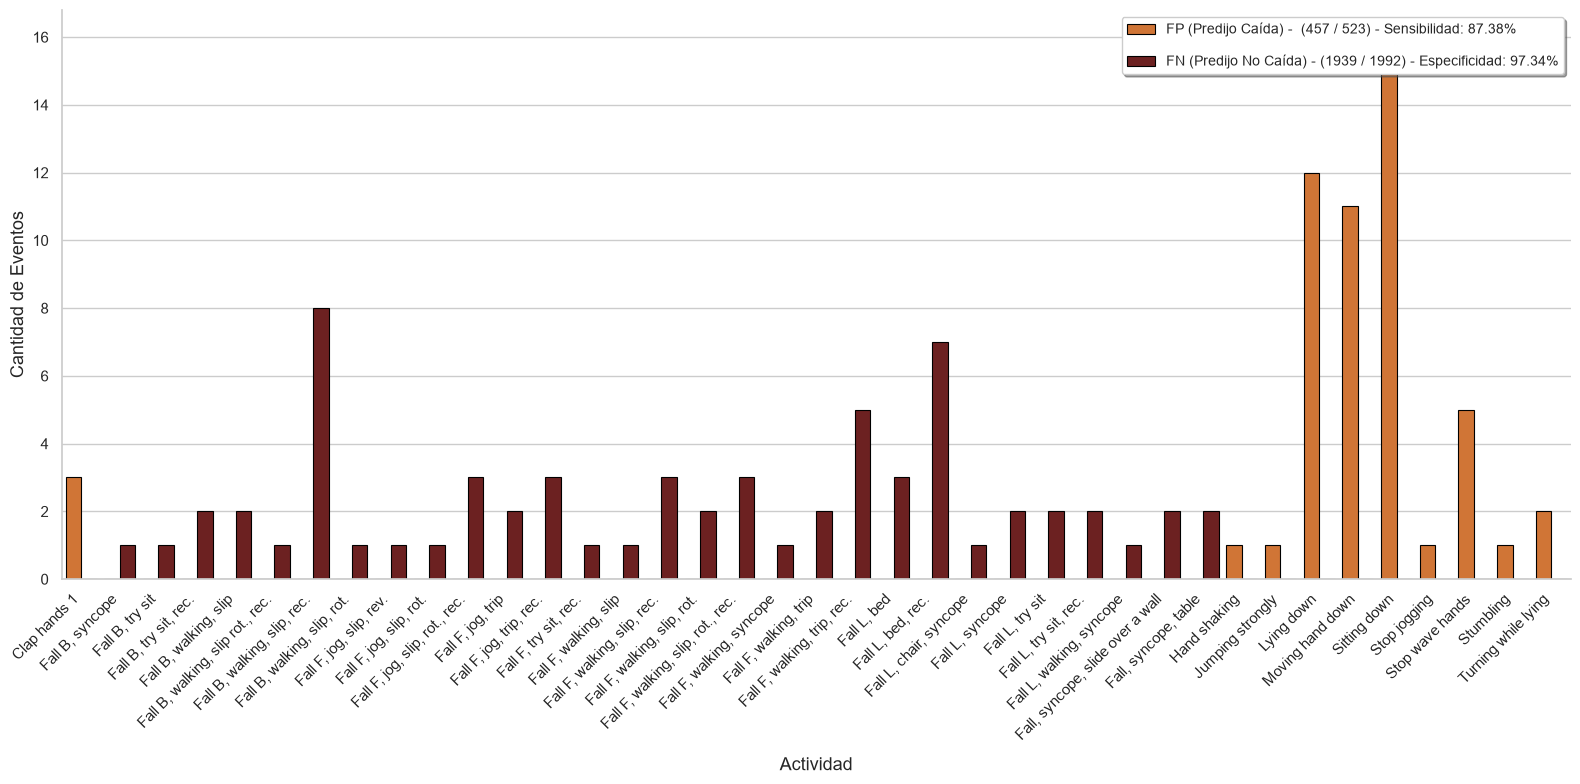

In [23]:

if metodo == "Promedio ponderado":
    y_pred = (y_pred_presion_full * K + y_pred_acelerometro_full * (1- K)) 
    y_pred = (y_pred > H1 ).astype(int)


if metodo == "Secuencial":
    filtro = (y_pred_acelerometro_full > H1).astype(int)
    y_pred = (y_pred_presion_full *filtro > H2 ).astype(int)
  
stats_perfom(y_pred, tags, activity)
